In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from src.features import BASE, DERIVADAS

df = pd.read_csv(RAIZ / "data" / "processed" / "concreto_features.csv")
TODAS = BASE + DERIVADAS

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_tr, idx_te = next(gss.split(df, groups=df["id_mezcla"]))
train = df.iloc[idx_tr].reset_index(drop=True)
test = df.iloc[idx_te].reset_index(drop=True)

print("Filas  train/test:", len(train), "/", len(test))
print("Mezclas train/test:", train["id_mezcla"].nunique(), "/", test["id_mezcla"].nunique())
print("Mezclas compartidas:", len(set(train["id_mezcla"]) & set(test["id_mezcla"])))

# Guardamos qué mezclas son de prueba, para reproducir la separación
pd.Series(sorted(test["id_mezcla"].unique()), name="id_mezcla").to_csv(
    RAIZ / "data" / "processed" / "ids_mezcla_prueba.csv", index=False)

pd.DataFrame({"train": train[["edad", "resistencia"]].describe().loc[["mean", "50%", "max"]].stack(),
              "test": test[["edad", "resistencia"]].describe().loc[["mean", "50%", "max"]].stack()})

Filas  train/test: 813 / 192
Mezclas train/test: 341 / 86
Mezclas compartidas: 0


train        test
mean edad          46.0123   45.197917
     resistencia   35.5746   33.877500
50%  edad          28.0000   28.000000
     resistencia   34.4000   32.880000
max  edad         365.0000  365.000000
     resistencia   82.6000   74.360000

In [2]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

X_tr, y_tr, g_tr = train[TODAS], train["resistencia"], train["id_mezcla"]

def evaluar(modelo, columnas):
    pred = cross_val_predict(modelo, train[columnas], y_tr,
                             cv=GroupKFold(n_splits=5), groups=g_tr, n_jobs=-1)
    return {"R2": r2_score(y_tr, pred),
            "RMSE": np.sqrt(mean_squared_error(y_tr, pred)),
            "MAE": mean_absolute_error(y_tr, pred)}

modelos = {
    "Abrams + edad": (TransformedTargetRegressor(regressor=LinearRegression(),
                      func=np.log, inverse_func=np.exp), ["a_lig", "log_edad"]),
    "Random Forest": (RandomForestRegressor(n_estimators=300, random_state=42), TODAS),
    "XGBoost": (XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4,
                subsample=0.8, colsample_bytree=0.8, random_state=42), TODAS),
    "LightGBM": (LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=15,
                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                 random_state=42, verbose=-1), TODAS),
}

res = pd.DataFrame({nombre: evaluar(m, c) for nombre, (m, c) in modelos.items()}).T.round(3)
res

,R2,RMSE,MAE
Abrams + edad,0.725,8.623,6.421
Random Forest,0.877,5.774,3.944
XGBoost,0.895,5.317,3.706
LightGBM,0.890,5.465,3.675


In [3]:
def evaluar_repetido(modelo, columnas, semillas=range(5)):
    rmse = []
    for s in semillas:
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=s)
        pred = cross_val_predict(modelo, train[columnas], y_tr,
                                 cv=cv, groups=g_tr, n_jobs=-1)
        rmse.append(np.sqrt(mean_squared_error(y_tr, pred)))
    return {"RMSE medio": np.mean(rmse), "desv. entre semillas": np.std(rmse, ddof=1)}

rep = pd.DataFrame({n: evaluar_repetido(m, c) for n, (m, c) in modelos.items()}).T.round(3)
rep

,RMSE medio,desv. entre semillas
Abrams + edad,8.684,0.024
Random Forest,5.943,0.077
XGBoost,5.607,0.165
LightGBM,5.620,0.169


In [4]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

cv_ajuste = GroupKFold(n_splits=5, shuffle=True, random_state=0)

def rmse_cv(modelo):
    pred = cross_val_predict(modelo, X_tr, y_tr, cv=cv_ajuste,
                             groups=g_tr, n_jobs=-1)
    return np.sqrt(mean_squared_error(y_tr, pred))

def obj_xgb(trial):
    m = XGBRegressor(
        n_estimators=trial.suggest_int("n_estimators", 200, 1000, step=100),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 7),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 30, log=True),
        random_state=42, n_jobs=1)
    return rmse_cv(m)

def obj_lgbm(trial):
    m = LGBMRegressor(
        n_estimators=trial.suggest_int("n_estimators", 200, 1000, step=100),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 4, 40),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 40),
        subsample=trial.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 30, log=True),
        random_state=42, n_jobs=1, verbose=-1)
    return rmse_cv(m)

estudios = {}
for nombre, obj in [("XGBoost", obj_xgb), ("LightGBM", obj_lgbm)]:
    est = optuna.create_study(direction="minimize",
                              sampler=optuna.samplers.TPESampler(seed=42))
    est.optimize(obj, n_trials=60)
    estudios[nombre] = est
    print(f"{nombre}: mejor RMSE (CV) = {est.best_value:.3f}")
    print(est.best_params, "\n")

c:\Users\danie\Documents\predictor-concreto\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


XGBoost: mejor RMSE (CV) = 5.287
{'n_estimators': 700, 'learning_rate': 0.056995600244882386, 'max_depth': 4, 'min_child_weight': 3, 'subsample': 0.9709632200372671, 'colsample_bytree': 0.549188417285999, 'reg_lambda': 4.399606697920975} 

LightGBM: mejor RMSE (CV) = 5.326
{'n_estimators': 600, 'learning_rate': 0.07556947110929192, 'num_leaves': 10, 'min_child_samples': 10, 'subsample': 0.9989615744301278, 'colsample_bytree': 0.5295543818700073, 'reg_lambda': 0.06200388229079964} 



In [5]:
import json

mejores = {n: e.best_params for n, e in estudios.items()}
(RAIZ / "models").mkdir(exist_ok=True)
with open(RAIZ / "models" / "mejores_hiperparametros.json", "w") as f:
    json.dump(mejores, f, indent=2)

def construir(nombre, params):
    if nombre == "XGBoost":
        return XGBRegressor(**params, random_state=42, n_jobs=1)
    return LGBMRegressor(**params, subsample_freq=1, random_state=42,
                         n_jobs=1, verbose=-1)

sin_ajustar = {"XGBoost": modelos["XGBoost"][0],
               "LightGBM": modelos["LightGBM"][0]}

filas = []
for nombre in ["XGBoost", "LightGBM"]:
    for etiqueta, m in [("sin ajustar", sin_ajustar[nombre]),
                        ("ajustado", construir(nombre, mejores[nombre]))]:
        rmses = []
        for s in range(1, 6):   # semillas distintas a la usada por Optuna
            cv = GroupKFold(n_splits=5, shuffle=True, random_state=s)
            pred = cross_val_predict(m, X_tr, y_tr, cv=cv,
                                     groups=g_tr, n_jobs=-1)
            rmses.append(np.sqrt(mean_squared_error(y_tr, pred)))
        filas.append({"modelo": nombre, "versión": etiqueta,
                      "RMSE medio": np.mean(rmses),
                      "desv.": np.std(rmses, ddof=1)})

pd.DataFrame(filas).round(3)

,modelo,versión,RMSE medio,desv.
0,XGBoost,sin ajustar,5.703,0.272
1,XGBoost,ajustado,5.555,0.201
2,LightGBM,sin ajustar,5.728,0.316
3,LightGBM,ajustado,5.523,0.257


In [6]:
from sklearn.base import clone

y_te, g_te = test["resistencia"], test["id_mezcla"]

finales = {
    "Abrams + edad": (modelos["Abrams + edad"][0], ["a_lig", "log_edad"]),
    "Random Forest": (modelos["Random Forest"][0], TODAS),
    "LightGBM ajustado": (construir("LightGBM", mejores["LightGBM"]), TODAS),
    "XGBoost ajustado": (construir("XGBoost", mejores["XGBoost"]), TODAS),
}

rng = np.random.default_rng(0)
filas, preds = [], {}
for nombre, (m, cols) in finales.items():
    mod = clone(m).fit(train[cols], y_tr)
    p = mod.predict(test[cols])
    preds[nombre] = p

    # Bootstrap por mezclas: se remuestrean mezclas completas, no filas sueltas
    e2 = pd.DataFrame({"g": g_te.values, "e2": (y_te.values - p) ** 2})
    agg = e2.groupby("g")["e2"].agg(["sum", "count"])
    s, c = agg["sum"].to_numpy(), agg["count"].to_numpy()
    boot = []
    for _ in range(2000):
        i = rng.integers(0, len(s), len(s))
        boot.append(np.sqrt(s[i].sum() / c[i].sum()))
    lo, hi = np.percentile(boot, [2.5, 97.5])

    filas.append({"modelo": nombre,
                  "R2": r2_score(y_te, p),
                  "RMSE": np.sqrt(mean_squared_error(y_te, p)),
                  "IC95 RMSE": f"{lo:.2f} – {hi:.2f}",
                  "MAE": mean_absolute_error(y_te, p)})

pd.DataFrame(filas).round(3)

,modelo,R2,RMSE,IC95 RMSE,MAE
0,Abrams + edad,0.763,7.532,6.22 – 8.84,5.603
1,Random Forest,0.907,4.715,4.03 – 5.37,3.392
2,LightGBM ajustado,0.904,4.802,3.97 – 5.60,3.394
3,XGBoost ajustado,0.913,4.556,3.76 – 5.26,3.237


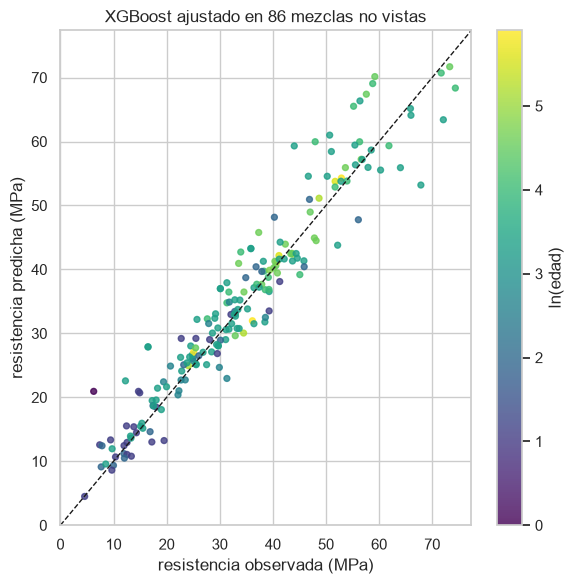

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

FIG = RAIZ / "reports" / "figures"
p = preds["XGBoost ajustado"]

plt.figure(figsize=(6, 6))
plt.scatter(y_te, p, c=test["log_edad"], cmap="viridis", s=18, alpha=0.8)
lim = [0, max(y_te.max(), p.max()) + 3]
plt.plot(lim, lim, "k--", lw=1)
plt.xlim(lim); plt.ylim(lim)
plt.xlabel("resistencia observada (MPa)")
plt.ylabel("resistencia predicha (MPa)")
plt.title("XGBoost ajustado en 86 mezclas no vistas")
plt.colorbar(label="ln(edad)")
plt.tight_layout()
plt.savefig(FIG / "07_prediccion_prueba.png", dpi=150)
plt.show()

In [8]:
res = test[["cemento", "agua", "a_lig", "edad", "resistencia"]].copy()
res["pred"] = preds["XGBoost ajustado"]
res["error"] = res["pred"] - res["resistencia"]

print("Mayores errores absolutos:")
display(res.reindex(res["error"].abs().sort_values(ascending=False).index).head(8).round(2))

res["rango_resist"] = pd.cut(res["resistencia"], [0, 20, 40, 60, 100],
                             labels=["<20", "20–40", "40–60", ">60"])
res["rango_edad"] = pd.cut(res["edad"], [0, 7, 28, 400],
                           labels=["≤7 d", "8–28 d", ">28 d"])

for col in ["rango_resist", "rango_edad"]:
    t = res.groupby(col, observed=True)["error"].agg(
        n="size", sesgo="mean", RMSE=lambda e: np.sqrt((e**2).mean()))
    print(f"\nPor {col}:")
    display(t.round(2))

Mayores errores absolutos:


,cemento,agua,a_lig,edad,resistencia,pred,error
103,355.0,145.0,0.31,28,44.03,59.310001,15.28
78,250.0,159.0,0.30,28,67.87,53.189999,-14.68
144,385.0,186.0,0.48,1,6.27,20.940001,14.67
102,387.0,157.0,0.31,56,47.97,59.970001,12.00
183,153.6,220.1,0.54,28,16.50,27.910000,11.41
149,154.0,220.0,0.54,28,16.50,27.870001,11.37
24,531.3,141.8,0.27,91,59.20,70.150002,10.95
124,200.0,180.0,0.90,28,12.25,22.580000,10.33



Por rango_resist:


,n,sesgo,RMSE
rango_resist,,,
<20,42,1.87,4.49
20–40,88,0.82,3.59
40–60,52,1.78,5.50
>60,10,-5.00,6.55



Por rango_edad:


,n,sesgo,RMSE
rango_edad,,,
≤7 d,43,0.88,4.21
8–28 d,98,0.82,4.71
>28 d,51,1.46,4.54


## Limitaciones observadas en la prueba reservada

- Una sola separación de 86 mezclas; la prueba resultó más favorable que la validación cruzada (RMSE 4.56 contra 5.5–5.7 MPa), y Abrams también mejoró en ella.
- La prueba no incluye resistencias superiores a 74 MPa. Por encima de 60 MPa (10 filas) el modelo subestima en promedio 5 MPa.
- Los modelos de árboles no extrapolan: con agua/ligantes = 0.90 (extremo del dataset) la predicción fue 22.6 MPa frente a 12.3 observados.
- Edad de 1 día prácticamente sin datos (2 ensayos): error de +14.7 MPa en el único caso de la prueba.
- Existen mezclas casi idénticas con identificadores distintos (diferencias de décimas de kg/m³); el agrupamiento exacto subestima la fuga de información.
- Algunas mezclas con dosificación similar difieren en 10-15 MPa: probable influencia de variables no registradas.
- Sesgo medio de +1 MPa (sobreestimación), pequeño frente al MAE de 3.2 MPa.